## Tutorial: modelling dispersion on a DNA-inspired $\pi$-stacking system with Bayesian quantum phase estimation

In this tutorial, we estimate the energy of the same $\pi$-stacked system as in the [BEAST-VQE](pi_stacking_beast_tutorial.ipynb) and [SHARP-qDRIFT](pi_stacking_sharp_sqdrift_tutorial.ipynb) tutorials, but now with quantum phase estimation (QPE), the textbook algorithm for computing energies on a fault-tolerant quantum computer. We compute the energy along a scan of the distance between the stacked fragments, from the equilibrium geometry to the dissociated limit, and use it to estimate the binding energy of the stacked dimer. The quantum chemistry problem is built with projective embedding, and the quantum circuits are simulated with Kvantify's memory-restricted simulator.

<div align="center"><img src="images/pi_stacking_image.png" alt="Thymine dimer extracted from the DNA atomistic model PDB 208D" width="450"></div>

**Why is this interesting?** The stacking of neighbouring nucleobases is one of the interactions that hold the DNA double helix together. It is a dispersion interaction: it is weak (about 1 kcal/mol for the dimer studied here) and it originates entirely from electron correlation. Mean-field methods, and many common density functionals such as B3LYP, miss it altogether, which makes $\pi$-stacking a classic stress test for correlated methods.

**How does QPE work?** QPE does not optimize a wave function. Instead, it applies the time-evolution operator $e^{-iHt}$ to an initial state, controlled by an ancilla qubit, and reads the energy from the phase the state picks up. The result is an eigenvalue of the Hamiltonian, and the probability of obtaining the ground-state energy is the squared overlap between the initial state and the ground state. QPE therefore needs a *good initial state*, and here the variational algorithms come into play: we prepare the initial state with orbital-optimized BEAST-VQE, and let QPE refine its energy. We use the Bayesian variant of QPE (BQPE), which needs a single ancilla qubit and updates a probability distribution of the energy after every measurement, until the uncertainty is below a chosen tolerance.

To keep the circuits small, we use the *paired-electron* (seniority-zero) approximation of the Hamiltonian, in which the electrons are kept in pairs. This is the same approximation that is used by BEAST-VQE, so that each spatial orbital is described by a single qubit and the BEAST-VQE state is a natural initial state for QPE.

**What you will learn:**
- how to reuse the embedded problems built (and persisted) by the other $\pi$-stacking tutorials;
- how to prepare an initial state with BEAST-VQE and refine its energy with Bayesian QPE;
- what the main knobs of QPE are: the Trotterized time evolution and the target uncertainty;
- how to turn the results into a binding curve, and compare QPE with the classical CASCI and CCSD(T) references and with the other quantum algorithms.

**Note:** quantum phase estimation is a preview feature in Qrunch. It is accessed through functions starting with an underscore (`_quantum_phase_estimation`, `_hamiltonian_encoder_creator`), and its interface may still change.

This notebook is one of a series of $\pi$-stacking tutorials living in the same folder: the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb), the [SHARP-qDRIFT tutorial](pi_stacking_sharp_sqdrift_tutorial.ipynb), and this QPE tutorial. They all build exactly the same embedded problems and share the persisted problem files, so the expensive embedding and active space step is only done once, by whichever notebook is run first.

All of the classes and methods we need will be found in the `qrunch` package. The documentation for the Kvantify Qrunch can be found [here](https://qrunch.docs.kvantify.net/index.html). We also define the folders where files will be stored, and set up the logger, which allows us to keep track of basic information when running the algorithms.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import qrunch as qc

result_path = Path("results")
result_path.mkdir(exist_ok=True, parents=True)

output_path = Path("output")
output_path.mkdir(exist_ok=True, parents=True)

qc.setup_logger(qc.LOGGER_INFO)

## Hardware requirements
With the paired-electron approximation, the QPE circuits act on one qubit per active orbital plus a single ancilla qubit, i.e. 17 qubits here, so the state vector is small. The circuits are, however, deep: the time evolution is implemented with many Trotter steps, and their number grows with the evolution time requested by BQPE. Simulating them is the most time-consuming quantum step of the $\pi$-stacking tutorials. On a GPU with the cuQuantum simulator, a BQPE run for a 16-orbital active space takes of the order of half a minute; on a CPU, expect it to take considerably longer. The embedding and active space step is stored in the shared `output` folder and reused by all the $\pi$-stacking tutorials.

### Setting up the experiment

The starting point is an .xyz file containing the 17 points of the scan. For the sake of execution time, we only use 7 of them: two points on the repulsive side, the minimum (scan point 2), three points on the attractive side and the dissociated limit (scan point 16). This subselection is the reason for a bit more complicated code in the experiment setup - otherwise we would just pass the xyz file name to `qc.build_reaction_configuration`.

This problem definition is shared across the different pi-stacking tutorials, and running it once will therefore speed up the execution of the other tutorials as well. Building the problem takes about 1h on a standard laptop. The choices are explained in more detail in the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb); keep them identical across the tutorials, otherwise the persisted problems are not reused.

In [2]:
reaction_path = Path("submodel_dt6dt7_scan.xyz")
# Normally we would use the reaction_path directly in the build_reaction_configuration step, but here we select specific geometries for the 17-point scan; 2 is the minimum, 16 the dissociated limit.
selected_geometries = [0, 1, 2, 4, 6, 9, 16]

def read_xyz_frames(xyz_path: Path) -> list[list[tuple[str, float, float, float]]]:
    """Return the atoms (element, x, y, z) of every frame of a multi-frame .xyz file."""
    lines = xyz_path.read_text().strip().splitlines()
    number_of_atoms = int(lines[0])
    frames = []
    for start in range(0, len(lines), number_of_atoms + 2):
        atom_lines = lines[start + 2 : start + 2 + number_of_atoms]
        frames.append([(element, float(x), float(y), float(z)) for element, x, y, z in map(str.split, atom_lines)])
    return frames

scan_frames = read_xyz_frames(reaction_path)
reaction = [scan_frames[index] for index in selected_geometries]
print(f"Selected scan points {selected_geometries} out of {len(scan_frames)}")

Selected scan points [0, 1, 2, 4, 6, 9, 16] out of 17


Now we build our reaction configuration. Here, we rely on [projective embedding theory](https://qrunch.docs.kvantify.net/docs/explanations/projective_embedding.html): the environment is handled through a DFT mean-field model, while the embedded atoms are treated explicitly with a correlated wave function method, here BEAST-VQE followed by QPE. In order to control this we need to define the embedding space by selecting the atoms that make up the embedded region, and define the spin difference (number of alpha minus beta electrons) and charge states of the system. Finally, we also need to set a basis set for the full calculation, which is modest in size here for acceptable run times of the tutorial. 

The embedded region consists of the two thymine rings, including their carbonyl oxygens and the hydrogens bound to the ring, i.e. the part of the molecules where the $\pi$-stacking happens. The methyl groups and the stubs of the sugar backbone are left to the DFT environment.

In [3]:
bset = "6-31+g"
# Embedded atoms (0-based) of each thymine: ring atoms, carbonyl oxygens and the H atoms on N3 and C6.
ring1 = [2, 3, 4, 5, 6, 7, 8, 10, 24, 25]
ring2 = [12, 13, 14, 15, 16, 17, 18, 20, 27, 28]
embedded_atoms = ring1 + ring2
charge = 0
spin = 0

reaction_config = qc.build_reaction_configuration(
    reaction=reaction,
    basis_set=bset,
    charge=charge,
    spin_difference=spin,
    embedded_atoms=embedded_atoms,
)

### Creating the problem with the problem builder

We use the [fluent build pattern](https://qrunch.docs.kvantify.net/docs/explanations/builder_pattern.html) to construct a `problem_builder_creator`. As in the BEAST-VQE tutorial, we calculate along a `reaction_path` with the `even_handed` approach, so that the active orbital assignment is consistent across all frames of the scan. This is crucial for a smooth potential energy surface.

Before going into details here, let us define a couple of parameters that are required for the quantum calculation and which we may want to play with later, specifically:
- the active space: 16 spatial orbitals with 5 alpha (and 5 beta) electrons. In the paired-electron approximation each spatial orbital becomes a single qubit, so the circuits act on 16 qubits, plus the ancilla qubit of BQPE;
- `shots` and `iterations` for the BEAST-VQE state preparation, as in the BEAST-VQE tutorial. A few iterations are enough to get a good overlap with the ground state; QPE takes care of the rest;
- `qpe_tolerance`: BQPE stops when the uncertainty (standard deviation) of the energy is below this value, here 1 mHa, which is below chemical accuracy (1.6 mHa);
- `max_time_step`: the largest time step of the Trotterized time evolution, which controls the Trotter error.

In [4]:
# (16 spatial orbitals, 10 electrons) active space: 16 qubits in the paired-electron encoding, plus one ancilla.
active_orbitals = 16
active_alpha_electrons = 5
shots = 1000
iterations = 10

qpe_tolerance = 1e-3
max_time_step = 0.1

The choices for the following cell, where we run the fluent builder pattern are:
- a DFT (B3LYP) full-system mean-field calculation;
- an orbital assignment based on the total weight of the atomic orbital contributions;
- MP2 natural orbitals for the embedded region (with a truncation of the virtual space);
- resolution of the identity for the full two-electron repulsion integrals;
- the active space defined above, followed by a conversion to dense integrals (which only happens in the active space).

**Important:** to reuse the orbitals and MP2 calculations that were already performed, every option that determines the stored data (functional, basis set, assignment tolerance, MP2 threshold, auxiliary basis, active space, ...) must be identical to the ones used in the earlier run.

In [5]:
dft_options = qc.options.DftCalculatorOptions(functional="b3lyp")
mp2_options = qc.options.MollerPlesset2CalculatorOptions(virtual_truncation_threshold=1e-6)

persister_path = output_path / "persister_data_sample"
persister_path.mkdir(exist_ok=True, parents=True)

reaction_builder_creator = (
    qc.problem_builder_creator()
    .reaction_path()
    .even_handed()
    .choose_full_system_solver()
    .dft(dft_options)
    .choose_orbital_assigner()
    .total_weight(assignment_tolerance=0.3)
    .choose_embedded_orbital_calculator()
    .moller_plesset_2(mp2_options)
    .choose_repulsion_integral_builder()
    .resolution_of_the_identity(auxiliary_basis="heavy-aug-cc-pvdz-ri")
    .add_problem_modifier()
    .active_space(active_orbitals, active_alpha_electrons)
    .add_problem_modifier()
    .to_dense_integrals()
)

When running calculations on embedded systems, it is useful to store the mean-field results and orbital assignment details so that they can be reused. This is the role of the `data_persister_manager`. We point it to the persister folder shared by all the $\pi$-stacking tutorials, and use `load_policy="fallback"`: the stored files are loaded when present, and generated only if they are missing.

In [6]:
reaction_builder_creator = (
    reaction_builder_creator.choose_data_persister_manager().file_persister(
        directory=persister_path,
        extension=".qdk",
        load_policy="fallback",
        overwriting_policy="overwrite",
    )
)

reaction_builder = reaction_builder_creator.create()

We now build the even-handed reaction path problem for the selected scan points. If the persisted files are already in place, for instance because one of the other $\pi$-stacking tutorials has been run, this step only loads them (check the log: it should not start new DFT or MP2 calculations). Without existing checkpoint files (the first time this is run) the following cell takes about 1h to finish.

In [7]:
reaction_problem = reaction_builder.build_restricted(reaction_config)
print(f"Built {len(reaction_problem.ground_state_problems)} problems for scan points {selected_geometries}")

2026-11-17 06:52:02 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.662, 20.544, 3.038),
    H: (8.644, 17.45535, 2.63535),
    H: (11.24096, 21.4485, 3.15236),
    N: (5.82, 20.104, 5.63),
    C: (5.875, 18.704, 5.589),
    O: (4.924, 18.004, 5.282),
    N: (7.065, 18.102, 5.901),
    C: (8.223, 18.748, 6.252),
    O: (9.251, 18.092, 6.395),
    C: (8.112, 20.206, 6.301),
    C: (6.933, 20.839, 5.991),
    H: (7.0923, 17.09285, 5.86987),
    H: (6.87564, 21.91678, 6.02962),
]
2026-11-17 06:52:02 [INFO] (kvantify.qrunch): Embedded atoms: [
    N: (9.359, 20.621, 2.68),
    C: (8.607, 19.479, 2.529),
    O: (7.436, 19.482, 2.212),
    N: (9.207, 18.286, 2.75),
    C: (10.496, 18.116, 3.111),
    O: (10.914, 16.977, 3.256),
    C: (11.24, 19.351, 3.252),
    C: (10.66

Built 7 problems for scan points [0, 1, 2, 4, 6, 9, 16]


### Preparing the initial state with BEAST-VQE

We first run orbital-optimized BEAST-VQE, as in the [BEAST-VQE tutorial](pi_stacking_beast_tutorial.ipynb), but with fewer iterations and without the PT2 correction: we only need its circuit (the initial state for QPE) and its optimized orbitals, in which the QPE Hamiltonian is expressed. The estimator and the sampler are based on the memory-restricted simulator.

In [8]:
estimator = qc.estimator_creator().memory_restricted().with_precise_defaults().create()
sampler = qc.sampler_creator().memory_restricted().with_precise_defaults().create()

beast_calculator = (
    qc.calculator_creator()
    .vqe()
    .iterative_with_orbital_optimization()
    .beast()
    .with_gate_selector_sampler(sampler)
    .with_gate_selector_shots(shots)
    .with_estimator(estimator)
    .with_options(qc.options.IterativeVqeOptions(max_iterations=iterations, force_all_iterations=True))
    .with_orbital_optimizer_estimator(estimator)
    .with_intermittent_orbital_optimizer_options(qc.options.IntermittentOrbitalOptimizerAlgorithmOptions.quick())
    .create()
)

beast_results = beast_calculator.calculate(reaction_problem)

2026-11-17 06:52:14 [INFO] (kvantify.qrunch): Run Adaptive Orbital Optimization VQE algorithm with 16 qubits:
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): Gate pool with 55 gates registered.
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/1000000 amplitudes, and the state vector simulation was exact.
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): Initial orbital optimization gradient norm: 9.109871494682569e-05
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): Running Adaptive VQE iteration: 1 / 10
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 1/1000000 amplitudes, and the state vector simulation was exact.
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): Running basic VQE
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): FFT Newton refinement converged in 1 iterations. 
2026-11-17 06:52:14 [INFO] (kvantify.qrunch): Optimal parameters found: [-3.07301375]
2026-11-17 06:52:14 [INFO] (kvantify.qrun

### Setting up Bayesian quantum phase estimation

QPE needs the time-evolution operator $e^{-iHt}$ as a circuit. This is the job of the *Hamiltonian encoder*. We use a second-order Suzuki-Trotter product formula, which splits the evolution into short time steps. With the `fixed_time_step` mode, the number of Trotter steps grows with the evolution time requested by BQPE, so that no step is longer than `max_time_step` (and at least `trotter_steps` steps are used). This keeps the Trotter error under control also for the long evolution times needed to reach a small uncertainty. The `hardcore_boson` decomposer turns each Trotter step into gates that act on the paired-electron (hard-core boson) qubits.

In [9]:
hamiltonian_encoder = (
    qc._hamiltonian_encoder_creator()
    .trotterization()
    .suzuki_trotter()
    .with_expansion_order(2)
    .with_options(
        qc.options.TrotterizationHamiltonianEncoderOptions(
            mode="fixed_time_step",
            trotter_steps=3,
            reference_time=1.0,
            max_time_step=max_time_step,
        )
    )
    .choose_trotterization_decomposer()
    .hardcore_boson()
    .create()
)

BQPE repeats short experiments: it evolves the initial state for a time $t$, controlled by the ancilla qubit, and measures the ancilla. Each outcome updates a probability distribution (the posterior) over the possible energies, and the next evolution time is chosen based on the current width of the posterior: the narrower it gets, the longer the evolution. BQPE stops when the standard deviation of the posterior is below `tolerance`, or after `max_number_of_iterations` experiments. The `convergence_rate` controls how aggressively the evolution time is increased.

The estimator evaluates the ancilla expectation values. The circuits contain complex amplitudes, so we switch off `use_real_numbers` of the memory-restricted simulator. With `with_total_estimator_shots(None)` the expectation values are computed exactly, i.e. without shot noise.

In [10]:
qpe_estimator = (
    qc.estimator_creator()
    .memory_restricted()
    .with_options(qc.options.MemoryRestrictedSimulatorOptions(use_real_numbers=False))
    .create()
)

bqpe_options = qc.options.BayesianQuantumPhaseEstimationOptions(
    convergence_rate=2.0,
    max_number_of_iterations=100,
    tolerance=qpe_tolerance,
)

qpe_calculator = (
    qc.calculator_creator()
    ._quantum_phase_estimation()
    .bayesian()
    .paired_electron_approximation()
    .with_estimator(qpe_estimator)
    .with_total_estimator_shots(None)
    .with_options(bqpe_options)
    .with_hamiltonian_encoder(hamiltonian_encoder)
    .create()
)

Now the chemistry definitions and the quantum algorithm come together. We pass the BEAST-VQE results to the QPE calculator: for each geometry, its circuit is used as the initial state, and its optimized orbitals define the Hamiltonian. The `qpe_results` object contains the energies together with their uncertainties.

This is the longest step of the tutorial, so it is a good moment for a coffee. While you wait, think about this: should the QPE energy be above or below the BEAST-VQE energy it starts from?

In [11]:
qpe_results = qpe_calculator.calculate(reaction_problem, beast_results)

2026-11-17 06:52:30 [INFO] (kvantify.qrunch): Initial prior estimate: 0.00000000±26.56436903
2026-11-17 06:52:30 [INFO] (kvantify.qrunch): BQPE iteration 1: checking Trotter error scaling.
2026-11-17 06:52:30 [INFO] (kvantify.qrunch): Trotter diagnostics: t=0.018822205, N=3, dt=0.0062740683, order=2; global-error scaling factor |t|*dt^p=7.4091603e-07; energy-bias scaling factor dt^p=3.9363934e-05. Unknown Hamiltonian/decomposition commutator prefactors: these are not error bounds and are not included in the BQPE posterior uncertainty.
2026-11-17 06:52:30 [ESSENTIAL] (kvantify.qrunch): Evolution time 0.018822205: using 3 dynamic Trotter steps.
2026-11-17 06:52:30 [INFO] (kvantify.qrunch): The memory restricted simulation used a maximum of 7760/1000000 amplitudes, and the state vector simulation was exact.
2026-11-17 06:52:30 [INFO] (kvantify.qrunch): Iteration 1/100: Current estimate is -5.14315880±23.44336894
2026-11-17 06:52:30 [INFO] (kvantify.qrunch): BQPE iteration 2: checking Trot

### Classical reference calculations

To judge the quantum results, we compare them with two well-established classical methods, applied to the same embedded active space:
- CASCI (complete active space configuration interaction) solves the active space problem exactly, including the broken electron pairs that the paired-electron approximation leaves out. Its cost grows exponentially with the size of the active space; with 16 orbitals and 10 electrons there are about 19 million determinants, which is still feasible on a laptop, but it takes a while.
- CCSD(T) (coupled cluster with singles, doubles and perturbative triples), the "gold standard" of quantum chemistry for weakly correlated systems such as this one. Its cost grows polynomially, so it remains feasible for much larger active spaces, where CASCI is out of reach.

The reference energies are the same for all the $\pi$-stacking tutorials, so they are stored in the `results` folder and only computed by whichever tutorial runs first.

In [ ]:
classical_result_file = result_path / f"pi_stacking_classical_{active_orbitals}o.json"
classical_data = json.loads(classical_result_file.read_text()) if classical_result_file.exists() else {}

if classical_data.get("geometry_indices") != selected_geometries:
    classical_calculators = {"CCSD(T)": qc.calculator_creator().coupled_cluster().ccsd_t().create()}
    # CASCI scales exponentially with the active space size; beyond about 16 orbitals rely on CCSD(T) only.
    if active_orbitals <= 16:
        classical_calculators["CASCI"] = qc.calculator_creator().configuration_interaction().standard().create()
    classical_data = {"geometry_indices": selected_geometries}
    for label, calculator in classical_calculators.items():
        classical_data[label] = [float(e) for e in calculator.calculate(reaction_problem).total_energies.values]
    classical_result_file.write_text(json.dumps(classical_data, indent=2))

classical_energies = {label: values for label, values in classical_data.items() if label != "geometry_indices"}

2026-11-17 08:55:53 [INFO] (kvantify.qrunch): Starting CCSD(T) ground-state problem calculation.
2026-11-17 08:55:53 [WARNING] (kvantify.qrunch): The Fock matrix is not diagonal (max off-diagonal element: 6.37e-02) to within the canonicality tolerance (1.00e-06). This may affect the accuracy to some degree. The reason for the discrepancy could be that the default SCF convergence thresholds were loosened or that you are using resolution-of-the-identity integrals, in which case the accuracy can be improved by using a larger auxiliary basis set. To remove the warning without changing the calculation parameters, you can increase the canonicality tolerance in the options.
2026-11-17 08:55:57 [INFO] (kvantify.qrunch):     CCSD active electrons correlation energy = -0.09625541648530371
2026-11-17 08:55:57 [INFO] (kvantify.qrunch):     (T) active electrons correlation energy = -0.0003847559086851689
2026-11-17 08:55:57 [INFO] (kvantify.qrunch):     CCSD(T) active electrons correlation energy =

### Extracting results

We first compare, geometry by geometry, the BEAST-VQE energy, the QPE energy with its uncertainty, and the classical reference energies. Since QPE projects onto an eigenstate of the Hamiltonian, its energy should be (within the uncertainty) below the variational BEAST-VQE energy it started from. The CASCI energy, on the other hand, should be lower than both, since it also includes the broken electron pairs.

In [ ]:
beast_energies = beast_results.total_energies.values
qpe_energies = qpe_results.total_energies.values
qpe_errors = qpe_results.total_energies.errors

print(f"{'Scan point':>10s} {'BEAST-VQE':>15s} {'QPE':>24s}" + "".join(f"{label:>15s}" for label in classical_energies))
for index, scan_point in enumerate(selected_geometries):
    row = f"{scan_point:>10d} {beast_energies[index]:>15.6f} {qpe_energies[index]:>15.6f} ± {qpe_errors[index]:.6f}"
    print(row + "".join(f"{energies[index]:>15.6f}" for energies in classical_energies.values()))

Scan point       BEAST-VQE                      QPE         OO-pFCI
         0    -1019.743814    -1019.743976 ± 0.000941
         1    -1019.749315    -1019.749584 ± 0.000919
         2    -1019.750010    -1019.750176 ± 0.000901
         4    -1019.749386    -1019.749553 ± 0.000873
         6    -1019.748849    -1019.749016 ± 0.000851
         9    -1019.748299    -1019.748469 ± 0.000828
        16    -1019.748229    -1019.748399 ± 0.000991


To plot the energy profile against a physical coordinate, we use the ring-ring separation of each geometry, defined as the distance between the centroids of the two thymine rings (atoms N1, C2, N3, C4, C5, C6 of each monomer). Since the rings are slipped with respect to each other, this distance is larger than the interplanar distance. The separations have been precomputed for all 17 points of the scan:

In [15]:
# Ring centroid-centroid distance (Å) of each of the 17 points in submodel_dt6dt7_scan.xyz.
ring_ring_separation = [
    4.226, 4.682, 5.145, 5.616, 6.090, 6.569, 7.051, 7.534, 8.020,
    8.508, 8.997, 9.487, 9.978, 10.470, 10.963, 11.456, 11.950,
]

separations = [ring_ring_separation[index] for index in selected_geometries]

The total energies are large numbers, while the interesting physics happens in the last few decimals. It is therefore more convenient to look at the energy relative to the dissociated limit, in kcal/mol: the depth of the minimum is the binding energy of the stacked dimer. The QPE uncertainties are shown as error bars.

**Where does the binding come from?** The Hartree-Fock reference energy tells us how much of the binding is due to electron correlation, and the classical CASCI and CCSD(T) curves show what the quantum algorithms should aim for. If the [BEAST-VQE](pi_stacking_beast_tutorial.ipynb) or [SHARP-qDRIFT](pi_stacking_sharp_sqdrift_tutorial.ipynb) tutorials have been run, their results are loaded from the `results` folder and added to the plot. Keep in mind that the QPE curve describes paired electrons only, while the BEAST-VQE tutorial adds a PT2 correction for the broken pairs, and SHARP-qDRIFT, CASCI and CCSD(T) are not restricted to paired electrons. Make a guess before running the cell!

              Reference (Hartree-Fock): binding energy = 0.00 kcal/mol
          OO-BEAST-VQE (initial state): binding energy = -1.12 kcal/mol
   OO-BEAST-VQE + PT2 (BEAST tutorial): binding energy = -1.04 kcal/mol
  SHARP-qDRIFT (SHARP-qDRIFT tutorial): binding energy = -0.44 kcal/mol
                                  BQPE: binding energy = -1.12 kcal/mol


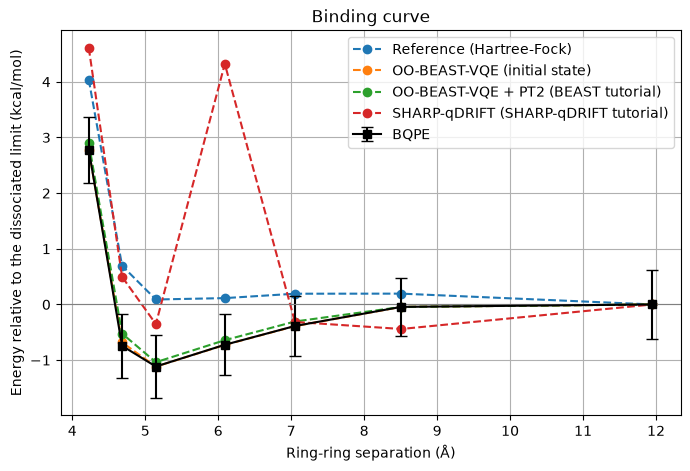

In [ ]:
hartree_to_kcal_per_mol = 627.5095

reference_energies = qpe_results.initial_total_energies.values

profiles = {
    "Reference (Hartree-Fock)": (selected_geometries, reference_energies),
    "OO-BEAST-VQE (initial state)": (selected_geometries, beast_energies),
}
for label, energies in classical_energies.items():
    profiles[label] = (selected_geometries, energies)

other_tutorials = {
    "OO-BEAST-VQE + PT2 (BEAST tutorial)": f"pi_stacking_beast_{active_orbitals}o.json",
    "SHARP-qDRIFT (SHARP-qDRIFT tutorial)": f"pi_stacking_sharp_sqdrift_{active_orbitals}o.json",
}
for label, file_name in other_tutorials.items():
    if (result_path / file_name).exists():
        data = json.loads((result_path / file_name).read_text())
        profiles[label] = (data["geometry_indices"], [energy["value"] for energy in data["total_energy_per_geometry"]])

plt.figure(figsize=(8, 5))
for label, (scan_points, energies) in profiles.items():
    # The last scan point is the dissociated limit.
    relative_energies = [(energy - energies[-1]) * hartree_to_kcal_per_mol for energy in energies]
    plt.plot([ring_ring_separation[point] for point in scan_points], relative_energies, marker="o", linestyle="--", label=label)
    print(f"{label:>38s}: binding energy = {min(relative_energies):.2f} kcal/mol")

qpe_relative_energies = [(energy - qpe_energies[-1]) * hartree_to_kcal_per_mol for energy in qpe_energies]
plt.errorbar(
    separations,
    qpe_relative_energies,
    yerr=[error * hartree_to_kcal_per_mol for error in qpe_errors],
    marker="s",
    color="black",
    capsize=4,
    label="BQPE",
)
print(f"{'BQPE':>38s}: binding energy = {min(qpe_relative_energies):.2f} kcal/mol")

plt.axhline(0.0, color="grey", linewidth=0.8)
plt.xlabel("Ring-ring separation (Å)")
plt.ylabel("Energy relative to the dissociated limit (kcal/mol)")
plt.title("Binding curve")
plt.legend()
plt.grid()
plt.show()

As in the other tutorials, the Hartree-Fock reference shows (essentially) no binding: the stacking of the two thymines only appears once electron correlation is included. Note the size of the QPE error bars: the binding energy (about 1.7 mHa) is close to the QPE tolerance (1 mHa), and the uncertainty of the binding energy combines the uncertainties at two geometries. Resolving weak interactions with QPE therefore requires a tight tolerance, i.e. long evolution times and deep circuits.

Finally, we save the results, together with the main parameters of the calculation, to a JSON file. The other $\pi$-stacking tutorials read this file to add the QPE binding curve to their own plots.

In [ ]:
final_data = {
    "charge": charge,
    "spin": spin,
    "basis_set": str(bset),
    "embedded_atom_indices": embedded_atoms,
    "cas": {
        "number_of_active_spatial_orbitals": active_orbitals,
        "number_of_active_alpha_electrons": active_alpha_electrons,
    },
    "simulator": "memory_restricted",
    "state_preparation": {"method": "OO-BEAST-VQE", "number_of_shots": shots, "number_of_iterations": iterations},
    "qpe_tolerance": qpe_tolerance,
    "max_time_step": max_time_step,
    "geometry_indices": selected_geometries,
    "total_energy_per_geometry": [
        {"value": float(value), "error": float(error)} for value, error in zip(qpe_energies, qpe_errors)
    ],
    "reference_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in reference_energies],
    "beast_energy_per_geometry": [{"value": float(e), "error": 0.0} for e in beast_energies],
    "nuclear_repulsion_per_geometry": qpe_results.nuclear_repulsions,
    "non_active_electrons_per_geometry": qpe_results.non_active_electrons_energies,
}

result_name = f"pi_stacking_qpe_{active_orbitals}o.json"
with open(result_path / result_name, "w") as f:
    json.dump(final_data, f, indent=2)
print(f"Saved results to {result_path / result_name}")

### Now it's your turn

Some ideas to explore, roughly ordered by the time they take:
- **Why do we need a good initial state?** Run QPE from the Hartree-Fock state instead, with `qpe_calculator.calculate(reaction_problem.ground_state_problems[2])`, i.e. without the BEAST-VQE result. Which energy do you get, and how does it compare with the QPE energy above? Hint: QPE returns *an* eigenvalue, with a probability given by the overlap of the initial state with the corresponding eigenstate.
- **How good does the initial state need to be?** Lower `iterations` of the BEAST-VQE state preparation to 3 or 5. Does QPE still find the same energy? Does it take longer?
- **Precision versus cost:** tighten `qpe_tolerance` to 0.5 mHa and see how the error bars of the binding curve shrink, and how the runtime grows. Try a single geometry first.
- **Trotter error:** increase `max_time_step` to 0.5. How much do the QPE energies change?
- **GPU simulation:** on a machine with an NVIDIA GPU, use `qc.estimator_creator().cuquantum_statevector()` as the QPE estimator, and the `locality_hardcore_boson(4)` decomposer, which packs the gates into blocks that the GPU simulator can fuse. How much faster is it? With a GPU, larger active spaces (e.g. 20 or 26 orbitals) also come within reach; there, CASCI is no longer feasible and CCSD(T) is the classical reference.
- **Compare with the other algorithms:** if you have not done so yet, run the [BEAST-VQE](pi_stacking_beast_tutorial.ipynb) and [SHARP-qDRIFT](pi_stacking_sharp_sqdrift_tutorial.ipynb) tutorials. They reuse the persisted problems and the classical references, and once their results are saved, rerunning the binding-curve cell above shows all quantum algorithms in one plot.
- **Different scan points:** editing `selected_geometries` changes the problem definition: the problems are built (and persisted) from scratch, which takes about an hour, and they will no longer match the ones used in the other $\pi$-stacking tutorials.